In [25]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.wkt import loads
from shapely.geometry import Polygon, MultiPolygon, LineString
from scipy.spatial import distance
from sklearn.cluster import DBSCAN
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score
from shapely.validation import make_valid
from sklearn.preprocessing import StandardScaler
import math
from joblib import Parallel, delayed  # For parallel processing


In [26]:
# load dataset
data = pd.read_csv('/content/parcels_abu_ftaira 1.csv')
roads = pd.read_csv('/content/roads_abu_ftaira 1.csv')


In [27]:
#Validate Data Columns
if "geom" not in data.columns:
    raise KeyError("Column 'geom' not found in the parcel dataset.")

In [28]:
road_geom_col = "geometry" if "geometry" in roads.columns else "geom" if "geom" in roads.columns else None
if not road_geom_col:
    raise KeyError("No valid geometry column ('geom' or 'geometry') found in the roads dataset.")


In [29]:
roads["geometry"] = roads[road_geom_col].apply(lambda x: loads(x) if pd.notnull(x) else None)


In [30]:
def extract_coordinates(wkt_str):
    try:
        geom = loads(wkt_str)
        if not geom.is_valid:
            geom = make_valid(geom)
        if isinstance(geom, MultiPolygon):
            geom = max(geom.geoms, key=lambda p: p.area)  # Use the largest polygon
        if isinstance(geom, Polygon):
            return list(geom.exterior.coords)
        else:
            return []  # Handle non-polygon geometries
    except Exception as e:
        print(f"Error processing geometry: {e}")
        return []


In [31]:
data["coordinates"] = Parallel(n_jobs=-1)(delayed(extract_coordinates)(wkt) for wkt in data["geom"])


In [32]:
def clean_intersection_points(coords):
    if len(coords) < 3:
        return coords
    cleaned_coords = []
    for i in range(len(coords)):
        prev_point = coords[i - 1] if i > 0 else None
        next_point = coords[i + 1] if i < len(coords) - 1 else None
        if prev_point and next_point:
            if (prev_point[0] == coords[i][0] == next_point[0]) or (prev_point[1] == coords[i][1] == next_point[1]):
                continue  # Skip redundant intersection point
        cleaned_coords.append(coords[i])
    return cleaned_coords


In [33]:
# Parallelize cleaning intersection points
data["cleaned_coordinates"] = Parallel(n_jobs=-1)(delayed(clean_intersection_points)(coords) for coords in data["coordinates"])

In [34]:
# Function to compute side lengths
def compute_side_lengths(coords):
    if len(coords) < 2:
        return []
    return [distance.euclidean(coords[i], coords[i + 1]) for i in range(len(coords) - 1)]

# Parallelize side length computation
data["side_lengths"] = Parallel(n_jobs=-1)(delayed(compute_side_lengths)(coords) for coords in data["cleaned_coordinates"])

In [35]:
def compute_angles(coords):
    """
    Compute interior angles of a polygon and calculate the fourth angle for quadrilaterals.
    """
    angles = []
    num_coords = len(coords) - 1  # Ignore the last point (as it's same as first to close the polygon)

    if num_coords < 3:
        return angles

    for i in range(num_coords):
        # Use three consecutive points to form an angle
        p1, p2, p3 = coords[i % num_coords], coords[(i + 1) % num_coords], coords[(i + 2) % num_coords]

        # Construct vectors
        v1 = np.array([p1[0] - p2[0], p1[1] - p2[1]])
        v2 = np.array([p3[0] - p2[0], p3[1] - p2[1]])

        # Calculate angle using arctan2
        angle_rad = np.arctan2(np.linalg.det([v1, v2]), np.dot(v1, v2))
        angle_deg = np.degrees(angle_rad)

        # Ensure angles are positive and within 0-360 degrees
        angle_deg = (angle_deg + 360) % 360

        angles.append(angle_deg)

    # If the polygon is a quadrilateral (4 sides), adjust the fourth angle
    if num_coords == 4 and len(angles) == 3:
        fourth_angle = 360 - sum(angles)
        angles.append(fourth_angle)

    return angles


In [36]:
# Parallelize angle computation
data["angles"] = Parallel(n_jobs=-1)(delayed(compute_angles)(coords) for coords in data["cleaned_coordinates"])

In [37]:
# Function to compute segment directions as N, NE, E, SE, S, SW, W, NW
def compute_directions(coords):
    if len(coords) < 2:
        return []
    compass_directions = ["E", "NE", "N", "NW", "W", "SW", "S", "SE"]
    directions = []
    for i in range(len(coords) - 1):
        p1, p2 = coords[i], coords[i + 1]
        dx = p2[0] - p1[0]
        dy = p2[1] - p1[1]
        angle = math.degrees(math.atan2(dy, dx))
        index = round(angle / 45) % 8  # Convert to 8 compass directions
        directions.append(compass_directions[index])
    return directions

In [38]:
# Parallelize direction computation
data["directions"] = Parallel(n_jobs=-1)(delayed(compute_directions)(coords) for coords in data["cleaned_coordinates"])

In [39]:
# Function to compute diagonal lengths
def compute_diagonal_lengths(coords):
    if len(coords) != 5:  # Need 4 unique coords (5 total to close the polygon)
        return []
    diag1 = distance.euclidean(coords[0], coords[2])
    diag2 = distance.euclidean(coords[1], coords[3])
    return [diag1, diag2]
 # Parallelize diagonal length computation
data["diagonal_lengths"] = Parallel(n_jobs=-1)(delayed(compute_diagonal_lengths)(coords) for coords in data["cleaned_coordinates"])

In [40]:
import geopandas as gpd
from shapely.geometry import Polygon
from pyproj import CRS

# Function to reproject coordinates to a meter-based CRS (UTM)
def reproject_to_utm(geometry, crs_from="EPSG:4326"):
    try:
        gdf = gpd.GeoDataFrame(geometry=[geometry], crs=crs_from)
        gdf = gdf.to_crs(gdf.estimate_utm_crs())  # Automatically determine best UTM zone
        return gdf.geometry.iloc[0]
    except Exception as e:
        print(f"Error in reprojection: {e}")
        return geometry  # Return original if reprojection fails

# Function to calculate area in square meters
def calculate_area(coords):
    if len(coords) < 3:
        return 0  # Not a valid polygon
    polygon = Polygon(coords)
    utm_polygon = reproject_to_utm(polygon)  # Convert to UTM for accurate area
    return utm_polygon.area  # Area in square meters

# Parallelize area computation with the new method
data["area_m2"] = Parallel(n_jobs=-1)(delayed(calculate_area)(coords) for coords in data["cleaned_coordinates"])


In [41]:
# Function to calculate perimeter
def calculate_perimeter(coords):
    if len(coords) < 3:
        return 0
    return sum(compute_side_lengths(coords))

# Parallelize perimeter computation
data["perimeter"] = Parallel(n_jobs=-1)(delayed(calculate_perimeter)(coords) for coords in data["cleaned_coordinates"])

In [42]:
# Parallelize perimeter computation
data["perimeter"] = Parallel(n_jobs=-1)(delayed(calculate_perimeter)(coords) for coords in data["cleaned_coordinates"])

# Function to calculate compactness
def calculate_compactness(area, perimeter):
    if perimeter == 0:
        return 0
    return (4 * np.pi * area) / (perimeter ** 2)

In [44]:
print(data.columns)


Index(['geom', 'gid', 'parcel_uid', 'n_name', 'coordinates',
       'cleaned_coordinates', 'side_lengths', 'angles', 'directions',
       'diagonal_lengths', 'area_m2', 'perimeter'],
      dtype='object')


In [46]:
# Vectorized compactness calculation
data["compactness"] = (4 * np.pi * data["area_m2"]) / (data["perimeter"] ** 2)

# Function to calculate circularity
def calculate_circularity(area, perimeter):
    if perimeter == 0:
        return 0
    return (4 * np.pi * area) / (perimeter ** 2)

# Vectorized circularity calculation
data["circularity"] = (4 * np.pi * data["area_m2"]) / (data["perimeter"] ** 2)

In [47]:
# Function to calculate major and minor axis lengths
def calculate_axis_lengths(coords):
    if len(coords) < 3:
        return 0, 0
    polygon = Polygon(coords)
    min_rect = polygon.minimum_rotated_rectangle
    coords = list(min_rect.exterior.coords)
    side_lengths = [distance.euclidean(coords[i], coords[i + 1]) for i in range(len(coords) - 1)]
    major_axis = max(side_lengths)
    minor_axis = min(side_lengths)
    return major_axis, minor_axis

# Parallelize axis length computation
data["major_axis"], data["minor_axis"] = zip(*Parallel(n_jobs=-1)(delayed(calculate_axis_lengths)(coords) for coords in data["cleaned_coordinates"]))

In [48]:
# Function to calculate elongation
def calculate_elongation(major_axis, minor_axis):
    if major_axis == 0:
        return 0
    return 1 - (minor_axis / major_axis)

# Vectorized elongation calculation
data["elongation"] = 1 - (data["minor_axis"] / data["major_axis"])

# Function to calculate aspect ratio
def calculate_aspect_ratio(major_axis, minor_axis):
    if minor_axis == 0:
        return 0
    return major_axis / minor_axis

# Vectorized aspect ratio calculation
data["aspect_ratio"] = data["major_axis"] / data["minor_axis"]

# Function to detect beveled corners
def detect_beveled_corner(side_lengths, avg_length, area, bevel_threshold=0.3):
    if not side_lengths:
        return False
    return any(length < avg_length * bevel_threshold and area > 0 for length in side_lengths)

# Function to classify parcel shape with subcategories
def classify_shape_refined(coords, side_lengths, diagonal_lengths, area, perimeter, compactness, circularity, elongation):
    if not side_lengths:
        return "Unknown"
    num_sides = len(coords) - 1
    min_length = min(side_lengths) if side_lengths else 1
    max_length = max(side_lengths) if side_lengths else 1
    aspect_ratio = max_length / min_length if min_length > 0 else 1
    avg_length = np.mean(side_lengths)
    side_length_variance = np.var(side_lengths) if len(side_lengths) > 1 else 0
    diagonal_variance = np.var(diagonal_lengths) if len(diagonal_lengths) == 2 else float('inf')
    has_bevel = detect_beveled_corner(side_lengths, avg_length, area)

    if num_sides == 3:
        return "Triangle"
    elif num_sides == 4:
        if has_bevel:
            return "Beveled Quadrilateral"
        if aspect_ratio < 1.1 and side_length_variance < avg_length / 15 and diagonal_variance < avg_length / 20:
            return "Square"
        elif aspect_ratio < 1.5 and diagonal_variance < avg_length / 20:
            return "Rectangle"
        elif aspect_ratio < 3:
            return "Elongated Rectangle"
        else:
            return "Long and Narrow"
    elif 5 <= num_sides <= 8:
        if has_bevel:
            return "Beveled Polygon"
        elif compactness > 0.8:
            return "Compact Polygon"
        else:
            return "Irregular Polygon"
    elif num_sides > 8:
        return "Complex Polygon"
    else:
        return "Irregular Shape"

Classification completed. Results saved to classified_parcels.csv.


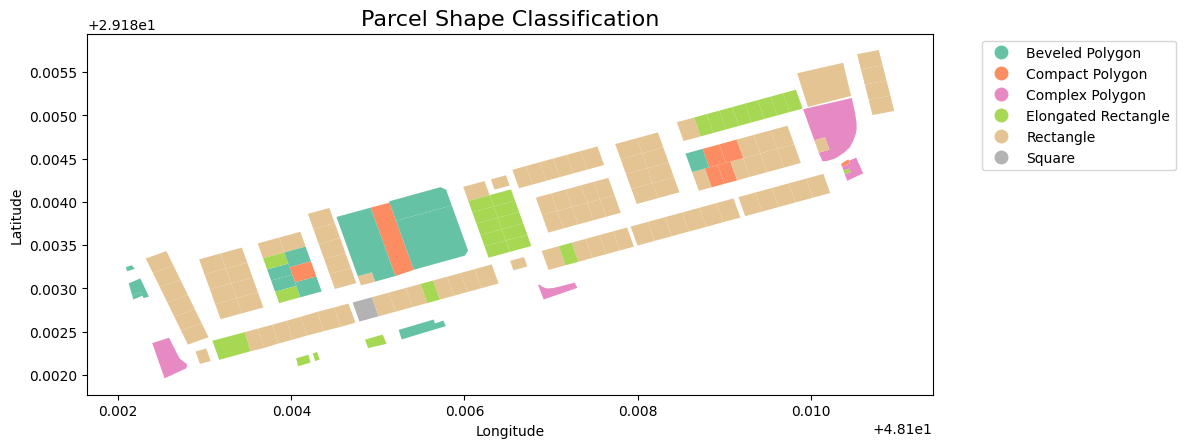

In [53]:
# Parallelize shape classification
data["shape_type"] = Parallel(n_jobs=-1)(delayed(classify_shape_refined)(row["cleaned_coordinates"], row["side_lengths"], row["diagonal_lengths"], row["area_m2"], row["perimeter"], row["compactness"], row["circularity"], row["elongation"]) for _, row in data.iterrows())

# Save results
data.to_csv("classified_parcels result.csv", index=False)
print("Classification completed. Results saved to classified_parcels.csv.")

# Visualization with Legend Outside the Map
# Convert cleaned coordinates to Shapely Polygons
data["geometry"] = data["cleaned_coordinates"].apply(lambda x: Polygon(x) if len(x) > 2 else None)

# Create a GeoDataFrame
gdf = gpd.GeoDataFrame(data, geometry="geometry")

# Plot the map
fig, ax = plt.subplots(figsize=(12, 10))
gdf.plot(column="shape_type", legend=True, ax=ax, cmap="Set2", legend_kwds={"bbox_to_anchor": (1.05, 1), "loc": "upper left"})

# Add title and labels
plt.title("Parcel Shape Classification", fontsize=16)
plt.xlabel("Longitude")
plt.ylabel("Latitude")

# Show the plot
plt.tight_layout()
plt.show()
